# 01 · 一团高斯，怎样落到照片上？

在空间里放一只气球，拿相机拍它：气球往后移，照片里的它会变小；把气球拉长、转个方向，照片上的轮廓也会跟着变。

3D Gaussian Splatting 的第一步，就在处理这样的几何关系。我们把每个高斯想成一团柔软的椭球，先找到它在屏幕上的**中心**，再算出它投下的**椭圆形状**。

## 这条学习路线

1. **本篇**：空间里的气球，怎样变成屏幕上的椭圆？
2. [光栅化与透明度混合](02_光栅化与透明度混合.ipynb)：椭圆覆盖的像素，应该涂什么颜色？
3. [可微渲染与图像拟合](03_可微渲染与图像拟合.ipynb)：让一组二维软画笔自己学着画图。
4. [交互点云选读](04_交互点云与实现边界.ipynb)：转动视角，追踪点云着色的计算过程。

在本目录运行 `uv sync --python 3.11.15`、`uv run jupyter lab`；VS Code 选择 `3d-gaussian-spatting/.venv/bin/python`。详细配置见[仓库入口](../README.md)。

## 先和相机约好方向

采用 OpenCV 风格：相机的 +Z 指向前方，+X 指向右边，+Y 指向下方。照片左上角是像素原点，横向记 u，纵向记 v。接下来观察的点都在相机前方，也就是相机坐标 z > 0。

In [ ]:
import math
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(42)

可以把拍照分成两步：**先换到相机的视角，再把三维点落到二维照片上。** 前一步由外参控制，后一步使用内参和透视除法。

### 中心和形状，分两路走

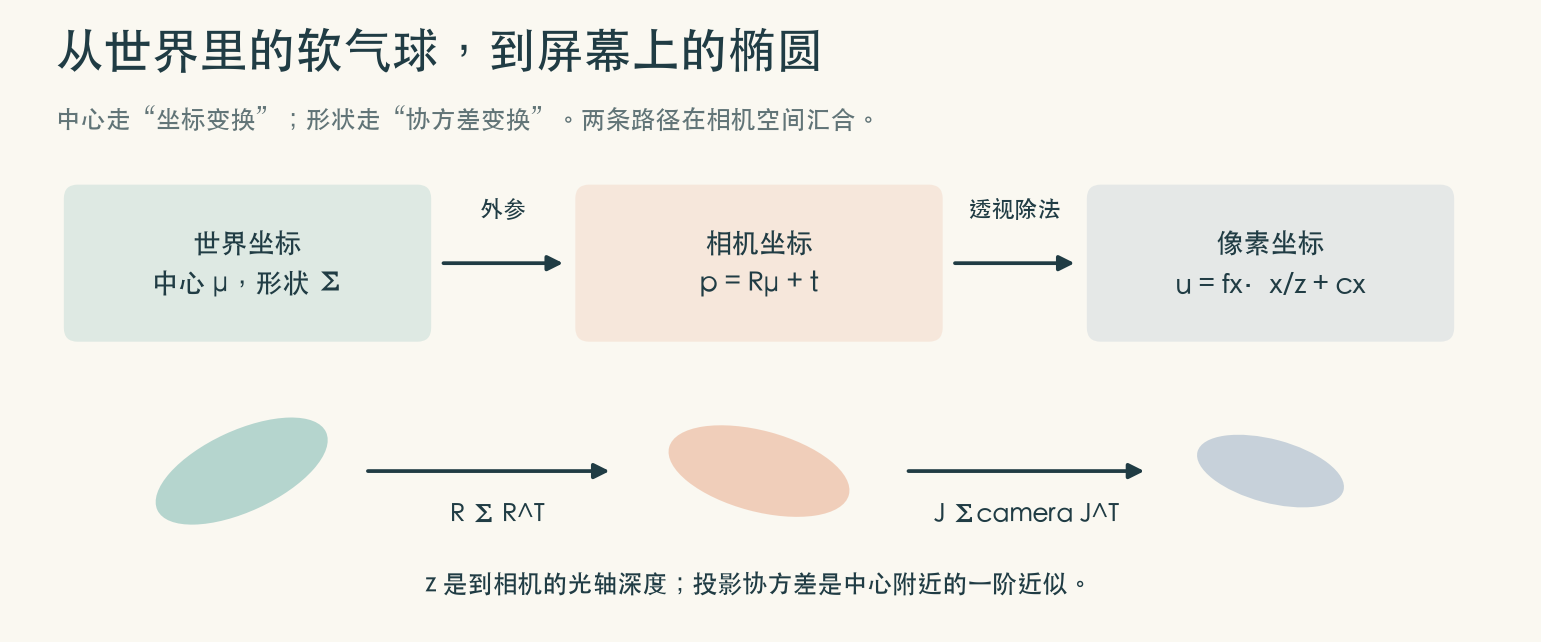

上面一条线追踪“气球放在哪”，下面一条线追踪“气球长什么样”。两条线最后合在一起，就得到屏幕上的完整椭圆。

## 1. 站到相机的位置，再看世界

世界坐标像地图上的地址，相机坐标像“它在我右边多少、前方多远”。换一个观察者，就要重新描述同一个点：

$$p_c=Rp_w+t.$$

R 调整朝向，t 调整原点。相机位于世界坐标 C 时，先从点的位置减去 C，再旋转：$p_c=R(p_w-C)$，所以 $t=-RC$。

下面相机在 `(0,0,1)`，朝 +Z 看。世界里 z=5 的点，在它眼前的深度就是 4。这个减法就是外参平移最直观的来源。

<details>
<summary>代码为什么用 4×4 矩阵？</summary>

给坐标补一个 1，就能把旋转和平移写进同一次矩阵乘法：

$$\begin{bmatrix}p_c\\1\end{bmatrix}=
\begin{bmatrix}R&t\\0&1\end{bmatrix}
\begin{bmatrix}p_w\\1\end{bmatrix}.$$

这叫齐次坐标。左上角 3×3 是旋转，右上角三项是平移。

</details>

### 实现：先换坐标，再落到照片上

下面的函数沿着这条路线排开：`build_view_matrix` 组装外参，`world_to_camera` 换视角，`project_camera_points` 做投影。

输入点排成 `(N,3)`。投影函数会检查正深度，帮助发现点跑到相机后方的情况。定义完函数后，先运行光轴附近的几个点看看。

In [ ]:
def _validate_points(points, name):
    points = np.asarray(points, dtype=np.float64)
    if points.ndim != 2 or points.shape[1] != 3:
        raise ValueError(f"{name} must have shape (N, 3), got {points.shape}")
    return points


def build_intrinsic_matrix(fx, fy, cx, cy):
    """Build a pinhole camera intrinsic matrix."""
    if fx <= 0 or fy <= 0:
        raise ValueError("fx and fy must be positive")

    return np.array([
        [fx, 0.0, cx],
        [0.0, fy, cy],
        [0.0, 0.0, 1.0],
    ], dtype=np.float64)


def build_view_matrix(rotation_world_to_camera, translation_world_to_camera):
    """Build a 4x4 world-to-camera rigid transform.

    The transform is p_camera = R_world_to_camera @ p_world + t_world_to_camera.
    """
    rotation = np.asarray(rotation_world_to_camera, dtype=np.float64)
    translation = np.asarray(translation_world_to_camera, dtype=np.float64)

    if rotation.shape != (3, 3):
        raise ValueError(f"rotation must have shape (3, 3), got {rotation.shape}")
    if translation.shape != (3,):
        raise ValueError(f"translation must have shape (3,), got {translation.shape}")

    view_matrix = np.eye(4, dtype=np.float64)
    view_matrix[:3, :3] = rotation
    view_matrix[:3, 3] = translation
    return view_matrix


def transform_points(points, transform):
    """Apply a 4x4 homogeneous transform to points with shape (N, 3)."""
    points = _validate_points(points, "points")
    transform = np.asarray(transform, dtype=np.float64)
    if transform.shape != (4, 4):
        raise ValueError(f"transform must have shape (4, 4), got {transform.shape}")

    homogeneous = np.concatenate(
        [points, np.ones((points.shape[0], 1), dtype=np.float64)], axis=1
    )
    transformed = homogeneous @ transform.T
    w = transformed[:, 3]
    if np.any(np.abs(w) < 1e-12):
        raise ValueError("homogeneous coordinate w is too close to zero")

    return transformed[:, :3] / w[:, None]


def world_to_camera(points_world, view_matrix):
    """Transform world-space points into camera space."""
    return transform_points(points_world, view_matrix)


def project_camera_points(points_camera, intrinsic_matrix, min_depth=1e-8):
    """Project camera-space points to pixel coordinates.

    Points behind the camera are rejected instead of silently using an
    absolute depth. This makes camera-convention mistakes visible early.
    """
    points_camera = _validate_points(points_camera, "points_camera")
    intrinsic_matrix = np.asarray(intrinsic_matrix, dtype=np.float64)
    if intrinsic_matrix.shape != (3, 3):
        raise ValueError(
            f"intrinsic_matrix must have shape (3, 3), got {intrinsic_matrix.shape}"
        )

    depth = points_camera[:, 2]
    if np.any(depth <= min_depth):
        raise ValueError("all camera-space points must have positive depth")

    projected_homogeneous = points_camera @ intrinsic_matrix.T
    return projected_homogeneous[:, :2] / projected_homogeneous[:, 2:3]


def project_world_points(points_world, view_matrix, intrinsic_matrix, min_depth=1e-8):
    """Transform world-space points and project them to pixel coordinates."""
    points_camera = world_to_camera(points_world, view_matrix)
    return project_camera_points(points_camera, intrinsic_matrix, min_depth)

In [ ]:
fx = fy = 120.0
width, height = 160, 120
cx, cy = width / 2, height / 2
intrinsics = build_intrinsic_matrix(fx, fy, cx, cy)
camera_position = np.array([0.0, 0.0, 1.0])
view_rotation = np.eye(3)
view = build_view_matrix(view_rotation, -view_rotation @ camera_position)
world_points = np.array([[0.0, 0.0, 5.0], [1.0, -0.5, 5.0]])
camera_points = world_to_camera(world_points, view)
pixels = project_world_points(world_points, view, intrinsics)
print("View matrix:\n", view)
print("Camera-space points:\n", camera_points)
print("Pixel coordinates:\n", pixels)

正对镜头的点落在照片的主点 `(cx,cy)`。离光轴越远，投影离主点也越远；下一步看看深度怎样改变这个偏移。

## 2. 为什么走远两倍，照片里的偏移会减半？

伸出一根手指，保持它在身体右侧，慢慢往前伸。它离视线中心的角度会变小。针孔投影用 x/z 和 y/z 描述这种关系：

$$u=f_x\frac{x}{z}+c_x,\qquad v=f_y\frac{y}{z}+c_y.$$

$f_x,f_y$ 把比例换成像素，$c_x,c_y$ 把原点移到主点。例如 `fx=500, cx=320, x=0.5, z=2`，横向偏移是 125 个像素，所以 u=445。

如果 x 不变、z 变成 4，偏移就减半。下面用深度 2、4、8 画出这三次投影。

<details>
<summary>内参矩阵里装着什么？</summary>

$$K=\begin{bmatrix}f_x&0&c_x\\0&f_y&c_y\\0&0&1\end{bmatrix}.$$

先算 $Kp_c$，再把前两项除以第三项，就得到 u、v。这里焦距以像素为单位，z 是相机坐标的光轴深度。

</details>

In [ ]:
depths = np.array([2.0, 4.0, 8.0])
depth_points = np.column_stack([np.full(3, 0.5), np.full(3, -0.25), depths + camera_position[2]])
depth_pixels = project_world_points(depth_points, view, intrinsics)
fig, ax = plt.subplots(figsize=(6, 4))
ax.scatter(depth_pixels[:, 0], depth_pixels[:, 1], color="teal")
ax.scatter([cx], [cy], marker="+", color="black")
for depth, pixel in zip(depths, depth_pixels):
    ax.annotate(f"z={depth:g}", pixel, xytext=(5, 5), textcoords="offset points")
ax.set_xlim(0, width)
ax.set_ylim(height, 0)
ax.set_aspect("equal")
ax.set_xlabel("u")
ax.set_ylabel("v")
ax.set_title("Perspective projection")
plt.show()
print("Offsets from principal point:\n", depth_pixels - np.array([cx, cy]))

三个点会逐步靠近主点：深度每翻一倍，横纵偏移各减半。读图时顺着照片的坐标方向看，v 向下增大。

## 3. 协方差：把气球的形状写成矩阵

先拿一个圆球，沿三个轴拉伸，再把它转个方向。三个尺度负责“拉多长”，旋转负责“朝哪边”：

$$S=\operatorname{diag}(s_x,s_y,s_z),\qquad
\Sigma_{3D}=RSS^TR^T.$$

为什么尺度出现两次？因为协方差记录的是**方差，也就是标准差的平方**。例如一个方向的尺度是 0.35，对应方差就是 $0.35^2=0.1225$。

旋转以后，长轴可能斜着穿过世界坐标的 x、y 轴。这种倾斜关系就体现在协方差的非对角元素中。

一个高斯还会携带中心、颜色和不透明度。后两项等到着色时再用，这一节先把形状捏出来。

### 实现：先拉伸，再绕 Z 轴转 45°

`get_rotation_matrix_from_euler` 把弧度角转换成旋转矩阵，顺序是 `Rz @ Ry @ Rx`；`compute_covariance_3d` 按公式组合 R 和 S。

下面使用三个不同的尺度，让椭球有一条明显的长轴，再观察旋转后的协方差矩阵。

In [ ]:
def get_rotation_matrix_from_euler(x, y, z):
    """
    简单的辅助函数：将欧拉角(弧度)转换为旋转矩阵 R
    这里为了简单直观，先使用欧拉角，实际项目中通常使用四元数(Quaternion)
    """
    R_x = np.array([[1, 0, 0],
                    [0, math.cos(x), -math.sin(x)],
                    [0, math.sin(x), math.cos(x)]])

    R_y = np.array([[math.cos(y), 0, math.sin(y)],
                    [0, 1, 0],
                    [-math.sin(y), 0, math.cos(y)]])

    R_z = np.array([[math.cos(z), -math.sin(z), 0],
                    [math.sin(z), math.cos(z), 0],
                    [0, 0, 1]])

    R = np.dot(R_z, np.dot(R_y, R_x))
    return R


def compute_covariance_3d(scale, rotation_matrix):
    """
    计算 3D 协方差矩阵 Sigma

    参数:
    scale: (3,) numpy array, 代表 x, y, z 三个主轴的标准差
    rotation_matrix: (3, 3) numpy array, 旋转矩阵 R

    返回:
    Sigma: (3, 3) 协方差矩阵
    """
    # 1. 构建缩放矩阵 S (对角矩阵)
    # S 是一个 3x3 矩阵，对角线上是 scale 的值，其他地方是 0
    S = np.diag(scale)
    R = rotation_matrix

    # 2. 计算协方差矩阵 Sigma = R * S * S^T * R^T
    # 提示：在 numpy 中，矩阵乘法可以使用 @ 符号，转置使用 .T
    Sigma = R @ S @ S.T @ R.T

    return Sigma

In [ ]:
scales = np.array([0.35, 0.10, 0.15])
gaussian_rotation = get_rotation_matrix_from_euler(0.0, 0.0, math.pi / 4)
covariance_3d = compute_covariance_3d(scales, gaussian_rotation)
print("3D covariance:\n", covariance_3d)
print("Principal variances:", np.linalg.eigvalsh(covariance_3d))
print("Squared scales:", scales ** 2)

特征值告诉我们三个主轴各有多宽，特征向量告诉我们主轴朝哪。这里的三份方差来自 `0.35²`、`0.10²`、`0.15²`；旋转改变方向，保留这些主轴方差。

## 4. 从一团椭球，到一片椭圆

中心投影好了，还要回答：中心旁边的一小片空间，落到屏幕上会铺开多大？

**雅可比矩阵 J 就是一张局部换算表。** 它记录 x、y、z 各动一点时，u、v 分别移动多少：

$$J=\begin{bmatrix}
f_x/z&0&-f_xx/z^2\\
0&f_y/z&-f_yy/z^2
\end{bmatrix}.$$

例如第一项 $f_x/z$ 表示：横向挪动同样距离，离相机越远，屏幕上的移动越小。

把这张换算表作用到形状上，就得到中心附近的一阶投影：

$$\Sigma_{2D}=J R_{wc}\Sigma_{3D}R_{wc}^T J^T.$$

先由 $R_{wc}$ 把椭球转到相机坐标，再由 J 压到二维屏幕。下面画出两个深度下的一倍标准差轮廓，比较它们的位置和大小。

### 实现：给中心附近的变化做一次换算

`view_space_pos` 提供相机坐标中的中心，J 在这个位置计算。`view_matrix` 参数传入外参的旋转部分，用来转动协方差。

中心已经经过完整外参变换，所以相机平移对投影的影响也进入了 J。

In [ ]:
def compute_2d_covariance(covariance_3d, view_matrix, focal_x, focal_y, view_space_pos):
    """
    计算 2D 投影协方差矩阵 (EWA Splatting)

    参数:
    covariance_3d: (3, 3) 3D 协方差矩阵
    view_matrix: (3, 3) 视图矩阵的旋转部分 (World to Camera Rotation)
    focal_x, focal_y: 相机焦距
    view_space_pos: (3,) 高斯中心在相机坐标系下的位置 (x, y, z)

    返回:
    cov2d: (2, 2) 2D 协方差矩阵
    """
    # 1. 提取相机坐标系下的坐标
    x, y, z = view_space_pos

    # 2. 构建雅可比矩阵 J (2x3)
    # J 描述了 3D 位置微小变化如何影响 2D 屏幕坐标
    # 公式:
    # J = [ fx/z   0    -(fx*x)/(z*z) ]
    #     [ 0    fy/z   -(fy*y)/(z*z) ]
    J = np.zeros((2, 3))
    # 第一行：u 对 x, y, z 的偏导数
    J[0, 0] = focal_x / z
    J[0, 1] = 0
    J[0, 2] = -(focal_x * x) / (z * z)

    # 第二行：v 对 x, y, z 的偏导数
    J[1, 0] = 0
    J[1, 1] = focal_y / z
    J[1, 2] = -(focal_y * y) / (z * z)

    # 3. 计算变换矩阵 T = J @ W
    # W 是 view_matrix (3x3)
    W = view_matrix
    T = J @ W

    # 4. 计算 2D 协方差: Sigma_2D = T @ Sigma_3D @ T.T
    cov2d = T @ covariance_3d @ T.T

    return cov2d

In [ ]:
from matplotlib.patches import Ellipse

fig, ax = plt.subplots(figsize=(7, 5))
for depth, color in [(3.0, "tomato"), (6.0, "teal")]:
    center_world = np.array([[0.2, -0.1, depth + camera_position[2]]])
    center_camera = world_to_camera(center_world, view)[0]
    center_pixel = project_world_points(center_world, view, intrinsics)[0]
    covariance_2d = compute_2d_covariance(covariance_3d, view[:3, :3], fx, fy, center_camera)
    eigenvalues, eigenvectors = np.linalg.eigh(covariance_2d)
    major = eigenvectors[:, -1]
    angle = np.degrees(np.arctan2(major[1], major[0]))
    ellipse = Ellipse(
        center_pixel, width=2 * np.sqrt(eigenvalues[-1]),
        height=2 * np.sqrt(eigenvalues[0]), angle=angle,
        facecolor=color, edgecolor=color, alpha=0.35, label=f"z={depth:g}",
    )
    ax.add_patch(ellipse)
    ax.scatter(*center_pixel, color=color)
    print(f"Depth {depth:g}, pixel covariance:\n{covariance_2d}")
ax.set_xlim(0, width)
ax.set_ylim(height, 0)
ax.set_aspect("equal")
ax.set_xlabel("u")
ax.set_ylabel("v")
ax.legend()
ax.set_title("Projected Gaussian footprints")
plt.show()

比较两条椭圆：远处那团高斯在屏幕上更小，中心也更靠近主点。沿同一条视线把中心推远时，足迹的线性尺寸约按 1/z 缩小，协方差约按 1/z² 缩小。

## 带着气球回看这四步

<details>
<summary>相机往前走一步，为什么外参里会出现负的平移？</summary>

相机坐标描述的是“相对我在哪”。相机位于 C 时，点先减去 C，再按相机朝向旋转，所以 t=-RC。

</details>

<details>
<summary>中心和形状分别怎样投影？</summary>

中心用针孔公式落到 `(u,v)`；形状用中心附近的 J 把三维协方差映射成二维协方差。

</details>

<details>
<summary>如果看到负深度，先检查哪里？</summary>

先看点是否在相机后方，再核对相机朝向和 world-to-camera 变换。保持深度的正负号，才能保留正确的前后关系。

</details>

现在照片上已经有了一片椭圆。下一篇给它上色：[光栅化与透明度混合](02_光栅化与透明度混合.ipynb)。